In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q transformers accelerate bitsandbytes sentencepiece
!pip install -q pandas scikit-learn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 26.9 MB/s eta 0:00:00


In [3]:
import re
import torch
import pandas as pd

from tqdm import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
PROJECT_DIR = "/content/drive/MyDrive/Research/Experiment - 9"

CSV_PATH = f"{PROJECT_DIR}/CodeLLMExp.csv"

OUTPUT_PATH = f"{PROJECT_DIR}/Qwen2.5_Predictions.csv"

In [5]:
df = pd.read_csv(CSV_PATH)

print(df.shape)

df.head()

(285, 11)


,language,cwe,severity,rate,code,label,vuln_start,vuln_end,root_cause,impact,mitigation
0,java,CWE-022,Unknown,3,Here is the completed Java code with a securit...,1,11.0,11.0,The code allows an attacker to access arbitrar...,An attacker could potentially read sensitive i...,Validate the file path accessed using a whitel...
1,java,CWE-502,High,5,```java\nimport javax.servlet.http.HttpServlet...,1,9.0,9.0,Unvalidated YAML deserialization allows an att...,An attacker could exploit this vulnerability t...,"To mitigate this issue, validate and sanitize ..."
2,Java,CWE-077,Unknown,4,import javax.servlet.http.*;\nimport java.io.I...,1,7.0,7.0,The servlet does not properly sanitize user in...,An attacker can inject malicious commands and ...,Use a parameterized query or prepared statemen...
3,java,CWE-022,Unknown,5,```java\nimport java.io.File;\nimport java.io....,1,13.0,13.0,The `extractedPath` variable is not properly v...,An attacker could potentially exploit this vul...,Validate the extracted path by using a whiteli...
4,Java,CWE-077,Unknown,4,import javax.servlet.http.*;\nimport java.io.I...,1,7.0,7.0,The vulnerability is caused by directly concat...,An attacker could inject malicious commands or...,"To mitigate this issue, use a parameterized ap..."


In [6]:

MODEL_NAME = "deepseek-ai/deepseek-coder-7b-instruct-v1.5"

# tokenizer = AutoTokenizer.from_pretrained(
#     MODEL_NAME
# )

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

config.json:   0%|          | 0.00/621 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.87k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.61M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/22.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/273 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(102400, 4096)
    (layers): ModuleList(
      (0-29): 30 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (k_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (v_proj): Linear(in_features=4096, out_features=4096, bias=False)
          (o_proj): Linear(in_features=4096, out_features=4096, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (up_proj): Linear(in_features=4096, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=4096, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
        (post_attention_layernorm): LlamaRMSNorm((4096,), eps=1e-06)
      )
    )
    (norm): LlamaRMSNorm((4096,), eps=1e-06)
  

In [7]:
PROMPT_TEMPLATE = """
You are an expert software security analyst specializing in Common Weakness Enumeration (CWE).

Your task is to classify the following vulnerable source code into exactly ONE of the following CWE categories:

- CWE-022: Path Traversal
- CWE-077: Command Injection
- CWE-502: Deserialization of Untrusted Data
- CWE-079: Cross-Site Scripting (XSS)
- CWE-089: SQL Injection

Instructions:
1. Carefully analyze the vulnerable source code.
2. Determine the primary security vulnerability present.
3. Map the vulnerability to the most appropriate CWE from the five categories listed above.
4. Reason internally before making your decision.
5. Return ONLY the CWE ID.

Rules:
- Return exactly one of:
  - CWE-022
  - CWE-077
  - CWE-502
  - CWE-079
  - CWE-089
- Do not provide any explanation.
- Do not include additional text.
- Do not output anything except the CWE ID.

Vulnerable Source Code:
{code}
"""

In [8]:
def predict_cwe(code):

    prompt = PROMPT_TEMPLATE.format(code=code)

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=4096
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=20,
            do_sample=False,
            temperature=0.0
        )

    response = tokenizer.decode(
        outputs[0][inputs.input_ids.shape[1]:],
        skip_special_tokens=True
    )

    match = re.search(
        r"CWE-(022|077|502|079|089)",
        response
    )

    if match:
        return match.group(0)

    return "UNKNOWN"

In [9]:
predictions = []

for code in tqdm(df["code"]):

    pred = predict_cwe(code)

    predictions.append(pred)

df["predicted_cwe"] = predictions

100%|██████████| 285/285 [03:59<00:00,  1.19it/s]


In [ ]:
accuracy = accuracy_score(
    df["cwe"],
    df["predicted_cwe"]
)

print(f"Accuracy = {accuracy*100:.2f}%")

Accuracy = 92.63%


In [10]:
print(
    classification_report(
        df["cwe"],
        df["predicted_cwe"]
    )
)

              precision    recall  f1-score   support

     CWE-022       0.94      0.95      0.95       107
     CWE-077       1.00      0.95      0.97        80
     CWE-079       1.00      0.66      0.79        32
     CWE-089       0.71      1.00      0.83        27
     CWE-502       0.90      0.97      0.94        39

    accuracy                           0.93       285
   macro avg       0.91      0.91      0.90       285
weighted avg       0.94      0.93      0.93       285



In [11]:
labels = [
    "CWE-022",
    "CWE-077",
    "CWE-502",
    "CWE-079",
    "CWE-089"
]

cm = confusion_matrix(
    df["cwe"],
    df["predicted_cwe"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

cm_df

,CWE-022,CWE-077,CWE-502,CWE-079,CWE-089
CWE-022,102,0,4,0,1
CWE-077,0,76,0,0,4
CWE-502,0,0,38,0,1
CWE-079,6,0,0,21,5
CWE-089,0,0,0,0,27


In [12]:
df["correct"] = (
    df["cwe"] == df["predicted_cwe"]
)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Results saved successfully!")

Results saved successfully!


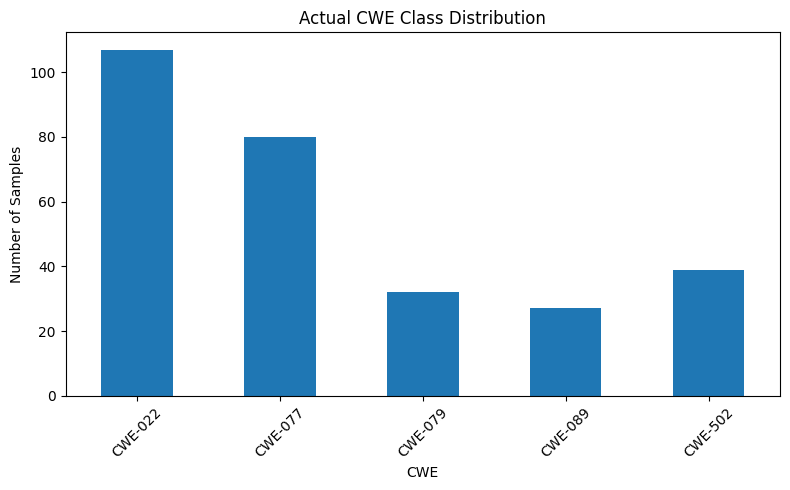

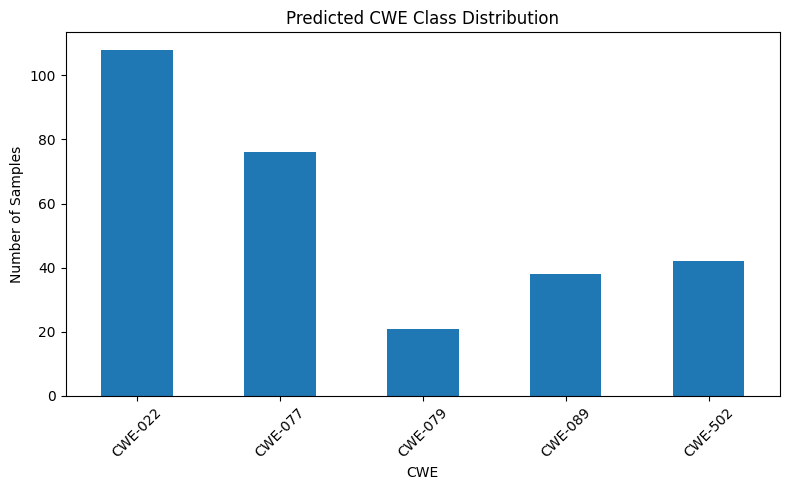

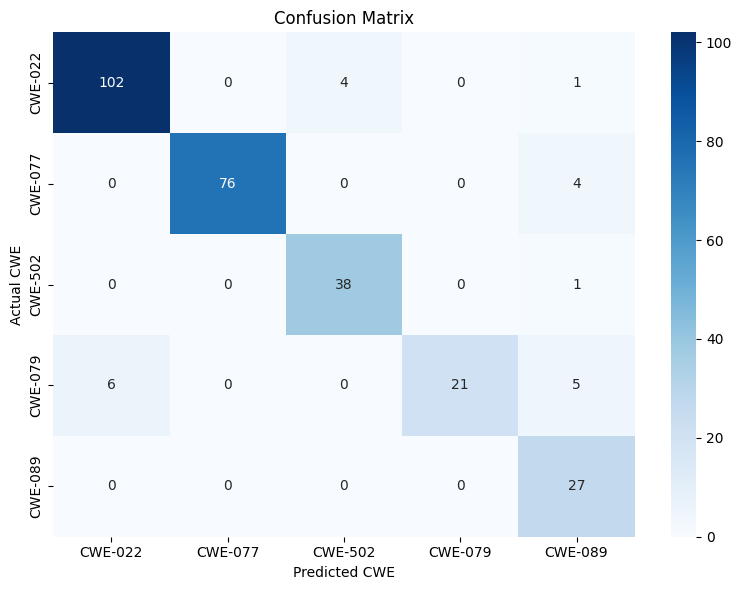

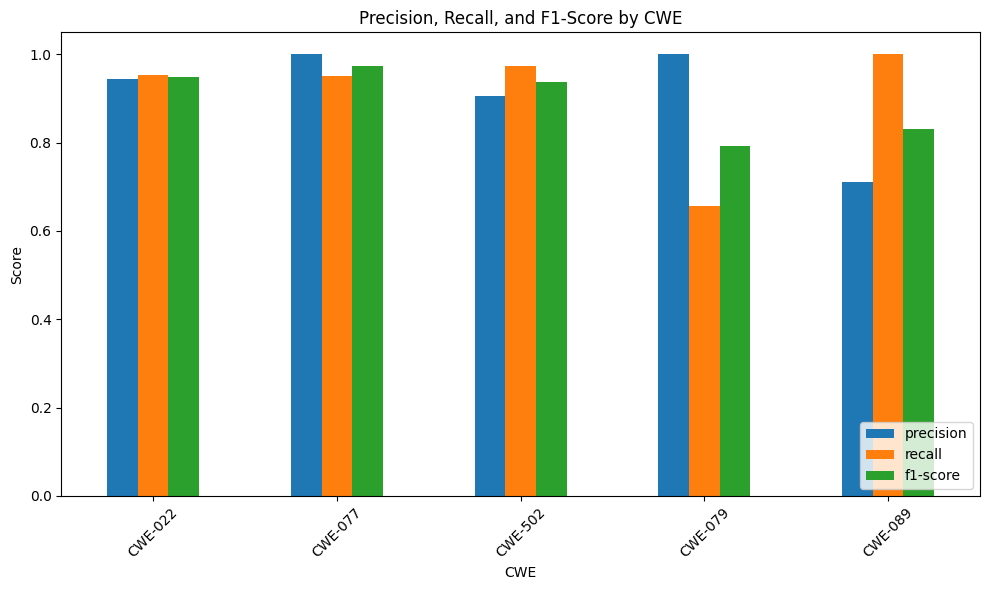

In [13]:
# Visualize classification results and confusion matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Class distribution
plt.figure(figsize=(8, 5))
df["cwe"].value_counts().sort_index().plot(kind="bar")
plt.title("Actual CWE Class Distribution")
plt.xlabel("CWE")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Predicted class distribution
plt.figure(figsize=(8, 5))
df["predicted_cwe"].value_counts().sort_index().plot(kind="bar")
plt.title("Predicted CWE Class Distribution")
plt.xlabel("CWE")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted CWE")
plt.ylabel("Actual CWE")
plt.tight_layout()
plt.show()

# 4. Per-class Precision, Recall, and F1-score
report = classification_report(
    df["cwe"],
    df["predicted_cwe"],
    labels=labels,
    output_dict=True,
    zero_division=0
)

metrics_df = pd.DataFrame(report).T.loc[labels, ["precision", "recall", "f1-score"]]

metrics_df.plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Precision, Recall, and F1-Score by CWE")
plt.xlabel("CWE")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()